# Capstone Part 1 — Lightning Talk #1
## Three Project Proposals and Basic Exploratory Data Analysis

**Scope:** Pitch + problem statement + audience + goals + data sources + data dictionaries + basic EDA. No preprocessing or model training.

**Important:** These datasets are candidates pending IA approval. Do not use information available only after the predicted event as predictors.

**Problem-statement standard:** Following the instructor’s Case Statement Guide, each proposal identifies the specific problem, numerical evidence, relevant audience, and historical timeframe. Objectives are listed separately, and proposed evaluation metrics are not presented as completed results.

**File loading:** The first code cell accepts either `match.csv` / `players.csv` / `movies_raw.csv` or the `(1).csv` copies.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

from pathlib import Path

# Accept original CSV names and uploaded copies with (1) suffix.
def csv_path(filename):
    path = Path(filename)
    if path.exists():
        return path
    alternative = path.with_name(f"{path.stem}(1){path.suffix}")
    if alternative.exists():
        return alternative
    raise FileNotFoundError(f"Cannot find {filename} or {alternative.name} in {Path.cwd()}")

soccer = pd.read_csv(csv_path("european_soccer_matches.csv"), low_memory=False)
dota_matches = pd.read_csv(csv_path("match.csv"))
dota_players = pd.read_csv(csv_path("players.csv"))
movies = pd.read_csv(csv_path("movies_raw.csv"))

for name, df in [("Soccer", soccer), ("Dota matches", dota_matches), ("Dota players", dota_players), ("Movies", movies)]:
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Soccer: 25,979 rows × 115 columns
Dota matches: 50,000 rows × 13 columns
Dota players: 500,000 rows × 73 columns
Movies: 17,978 rows × 16 columns


## Reusable EDA Functions

The following functions report data types, missing values, target distribution, numerical correlations, and outliers. Correlation is descriptive, **not** evidence of causality or suitability for prediction.

In [2]:
def overview(df):
    print("Shape:", df.shape, "| Duplicate rows:", df.duplicated().sum())
    print("Numeric columns:", len(df.select_dtypes(include="number").columns))
    print("Non-numeric columns:", len(df.select_dtypes(exclude="number").columns))
    display(df.head())
    display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "missing_%": df.isna().mean().mul(100).round(2)}))

def target_plot(df, target, categorical=True):
    plt.figure(figsize=(8, 4))
    if categorical:
        counts = df[target].value_counts(dropna=False)
        sns.barplot(x=counts.index.astype(str), y=counts.values)
        plt.ylabel("Records")
        display(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)}))
    else:
        sns.histplot(df[target].dropna(), bins=35)
        plt.ylabel("Movies")
        print(df[target].describe())
    plt.title(f"Target distribution: {target}")
    plt.xlabel(target)
    plt.tight_layout()
    plt.show()

def numeric_correlations(df, target, top=12):
    numeric = df.select_dtypes(include="number")
    if target not in numeric.columns:
        print("Target is not numeric; use an explicitly defined binary indicator for exploratory correlation.")
        return
    corr = numeric.corr(numeric_only=True)
    display(corr[target].drop(target).dropna().reindex(corr[target].drop(target).abs().sort_values(ascending=False).index).head(top).to_frame("correlation"))
    selected = corr[target].dropna().abs().sort_values(ascending=False).head(9).index.tolist()
    plt.figure(figsize=(9, 6))
    sns.heatmap(numeric[selected].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation among selected numeric variables")
    plt.tight_layout()
    plt.show()

def outlier_summary(df, columns):
    rows = []
    for col in columns:
        x = pd.to_numeric(df[col], errors="coerce").dropna()
        if x.empty: continue
        q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
        outside = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
        rows.append({"feature": col, "IQR_outliers": int(outside), "percent": round(100 * outside / len(x), 2)})
    display(pd.DataFrame(rows))
    if columns:
        fig, axes = plt.subplots(1, len(columns), figsize=(max(6, 4 * len(columns)), 4))
        if len(columns) == 1: axes = [axes]
        for ax, col in zip(axes, columns):
            sns.boxplot(y=pd.to_numeric(df[col], errors="coerce"), ax=ax)
            ax.set_title(col)
        plt.tight_layout(); plt.show()

# Proposal 1: European Soccer — Match Outcome Prediction

### SMART-informed problem statement (historical study scope)
Across 25,979 recorded European league matches (2008–2016), 11,917 ended in home wins, 6,596 in draws and 7,466 in away wins. Football analysts evaluating fixtures before kickoff must assess three possible outcomes, and an incorrect assessment can reduce the usefulness of match previews and planning. The challenge is to quantify how much reliable pre-match information can distinguish these outcomes across the recorded seasons.

**Time boundary:** The analysis in Lightning Talk #1 uses the uploaded historical dataset; predictive modeling is reserved for the final-project phase. No submission deadline is assumed beyond the instructor’s schedule.

### Measurable project objectives
1. Measure the proportion of home wins, draws and away wins across 25,979 matches and by season.
2. Identify pre-kickoff features with adequate coverage and compare outcome rates across their groups.
3. During the final project, evaluate three-class predictions against a majority-class baseline using macro-F1 and accuracy.

**Scope note:** The figures describe the uploaded historical dataset, not a measured business loss. The modeling targets and performance metrics are proposed goals, not achieved results.

### Potential audience
Football analysts, sports researchers, clubs and interested fans.

### Goals and success criteria
Build a three-class classification baseline later; compare against a majority-class baseline; assess macro-F1 and balanced accuracy.

### Data source and collection
[https://www.kaggle.com/datasets/hugomathien/soccer](https://www.kaggle.com/datasets/hugomathien/soccer). Downloaded CSV or converted original source to CSV.

### Data information
European Soccer Database, converted Match table to CSV; 25,979 rows × 115 columns.

### Target
`match_result`: Home Win / Draw / Away Win, **derived from the two final scores for labeling only**. It is categorical, with three classes. **Do not use final goals, in-match event statistics, or other post-match fields as predictors.**

### Data dictionary
The following table describes every original column by its functional group. The code below also creates a full 115-row per-column dictionary.

| Group | Columns | Meaning |
|---|---|---|
| Identifiers | `id`, `match_api_id`, `country_id`, `league_id`, `home_team_api_id`, `away_team_api_id` | Record, league and team identifiers |
| Scheduling | `season`, `stage`, `date` | Season, match round and date |
| Outcomes | `home_team_goal`, `away_team_goal` | Final scores; target creation only |
| Lineups | `home_player_1`…`11`, `away_player_1`…`11` | Player identifiers |
| Positions | `home_player_X1`…`X11`, `home_player_Y1`…`Y11`, away equivalents | Recorded player coordinates |
| Events | `goal`, `shoton`, `shotoff`, `foulcommit`, `card`, `cross`, `corner`, `possession` | Match events; leakage for pre-match prediction |
| Odds | `B365H/D/A`, `BWH/D/A`, `IWH/D/A`, `LBH/D/A`, `PSH/D/A`, `WHH/D/A`, `SJH/D/A`, `VCH/D/A`, `GBH/D/A`, `BSH/D/A` | Bookmaker odds for home/draw/away; availability/timing must be checked |

Shape: (25979, 115) | Duplicate rows: 0
Numeric columns: 105
Non-numeric columns: 10


,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


,dtype,missing,missing_%
id,int64,0,0.00
country_id,int64,0,0.00
league_id,int64,0,0.00
season,str,0,0.00
stage,int64,0,0.00
...,...,...,...
GBD,float64,11817,45.49
GBA,float64,11817,45.49
BSH,float64,11818,45.49
BSD,float64,11818,45.49


,count,percent
match_result,,
Home Win,11917,45.87
Away Win,7466,28.74
Draw,6596,25.39


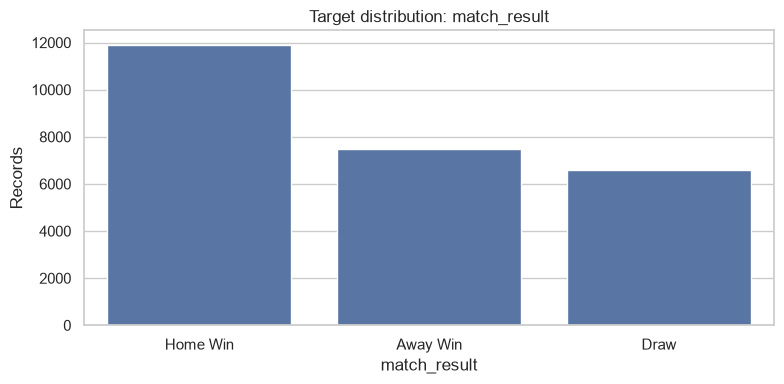

Missing values by column:


,missing
PSD,14811
PSA,14811
PSH,14811
BSH,11818
BSA,11818
...,...
home_team_api_id,0
match_api_id,0
league_id,0
id,0


Top original column types:


float64    96
str        10
int64       9
Name: count, dtype: int64

In [3]:
soccer_eda = soccer.copy()
soccer_eda["match_result"] = np.select([soccer_eda.home_team_goal > soccer_eda.away_team_goal, soccer_eda.home_team_goal < soccer_eda.away_team_goal], ["Home Win", "Away Win"], default="Draw")
overview(soccer)
target_plot(soccer_eda, "match_result")
print("Missing values by column:")
display(soccer.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Top original column types:")
display(soccer.dtypes.value_counts())

Descriptive correlations with home-win indicator (not multiclass model results):


,correlation
IWA,0.326608
BWA,0.321475
B365A,0.319901
IWH,-0.291556
BWH,-0.288489
B365H,-0.284111
IWD,0.204517
B365D,0.197694
BWD,0.196526
stage,0.012877


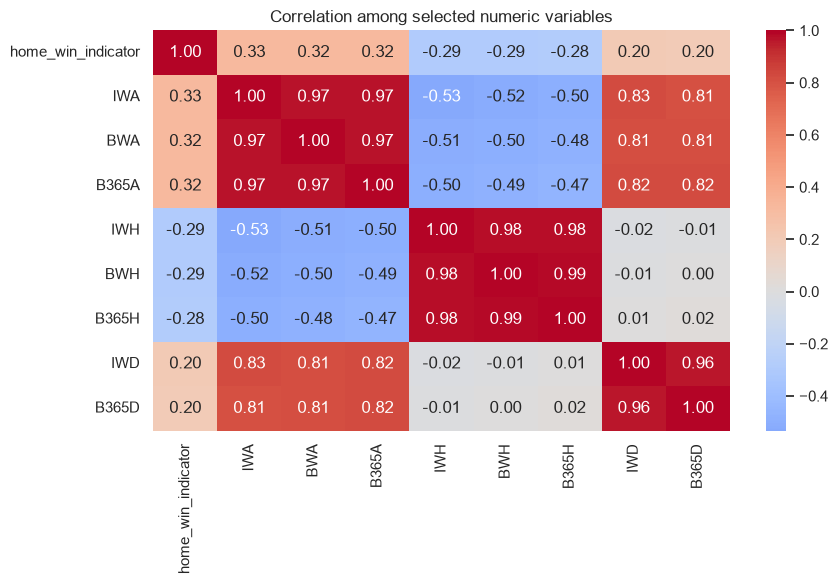

Outlier review (goals shown for outcome description only):


,feature,IQR_outliers,percent
0,home_team_goal,2056,7.91
1,away_team_goal,79,0.30
2,B365H,2210,9.78


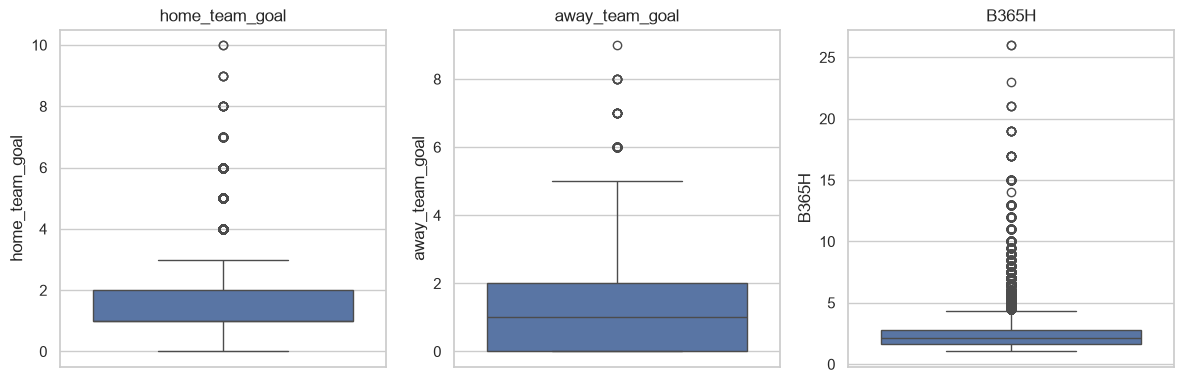

Pre-match bookmaker odds are only suitable if available at the defined prediction time.
Final goals and in-match events are excluded from predictive feature correlations.


In [4]:
# Restrict this pre-match exploration to plausibly available predictors.
# Goals, match events, lineup coordinates, and final-score-derived variables are excluded.
soccer_pre_match = ["stage", "B365H", "B365D", "B365A", "BWH", "BWD", "BWA", "IWH", "IWD", "IWA"]
soccer_pre_match = [c for c in soccer_pre_match if c in soccer_eda.columns]
soccer_corr = soccer_eda[soccer_pre_match].select_dtypes(include="number").copy()
soccer_corr["home_win_indicator"] = (soccer_eda["match_result"] == "Home Win").astype(int)
print("Descriptive correlations with home-win indicator (not multiclass model results):")
numeric_correlations(soccer_corr, "home_win_indicator")
print("Outlier review (goals shown for outcome description only):")
outlier_summary(soccer_eda, [c for c in ["home_team_goal", "away_team_goal", "B365H"] if c in soccer_eda])
print("Pre-match bookmaker odds are only suitable if available at the defined prediction time.")
print("Final goals and in-match events are excluded from predictive feature correlations.")

In [5]:
def soccer_definition(col):
    if col in {"home_team_goal", "away_team_goal"}: return "Final score; label information only"
    if col.endswith(("H", "D", "A")) and col[:2] in {"B3", "BW", "IW", "LB", "PS", "WH", "SJ", "VC", "GB", "BS"}: return "Bookmaker match-result odds"
    if "player_X" in col or "player_Y" in col: return "Recorded lineup field coordinate"
    if "player_" in col: return "Lineup player identifier"
    if col in {"goal", "shoton", "shotoff", "foulcommit", "card", "cross", "corner", "possession"}: return "In-match event field (not pre-match predictor)"
    return {"id":"Row identifier", "country_id":"Country identifier", "league_id":"League identifier", "season":"Season", "stage":"Match round", "date":"Match date", "match_api_id":"Match API identifier", "home_team_api_id":"Home team identifier", "away_team_api_id":"Away team identifier"}.get(col, "Source-defined field; verify exact meaning")
display(pd.DataFrame({"column": soccer.columns, "description": [soccer_definition(c) for c in soccer.columns], "dtype": soccer.dtypes.astype(str).values, "missing": soccer.isna().sum().values}))

,column,description,dtype,missing
0,id,Row identifier,int64,0
1,country_id,Country identifier,int64,0
2,league_id,League identifier,int64,0
3,season,Season,str,0
4,stage,Match round,int64,0
...,...,...,...,...
110,GBD,Bookmaker match-result odds,float64,11817
111,GBA,Bookmaker match-result odds,float64,11817
112,BSH,Bookmaker match-result odds,float64,11818
113,BSD,Bookmaker match-result odds,float64,11818


# Proposal 2: Dota 2 — Winning Team Prediction

### SMART-informed problem statement (historical study scope)
In a sample of 50,000 Dota 2 matches, Radiant won 25,943 games (51.9%) and Dire won 24,057 (48.1%). Esports coaches and analysts need to assess team matchups after hero selection but before gameplay, when the eventual winner is still uncertain. The challenge is to determine whether hero composition provides more useful information than simply predicting the more frequent winner in this historical sample.

**Time boundary:** The analysis in Lightning Talk #1 uses the uploaded historical dataset; predictive modeling is reserved for the final-project phase. No submission deadline is assumed beyond the instructor’s schedule.

### Measurable project objectives
1. Measure Radiant/Dire win proportions in the 50,000 recorded matches.
2. Summarize hero-pick frequency and win rates using the ten linked player records per match.
3. During the final project, compare pre-match hero-based predictions with a majority-class baseline using accuracy and F1.

**Scope note:** The figures describe the uploaded historical dataset, not a measured business loss. The modeling targets and performance metrics are proposed goals, not achieved results.

### Potential audience
Esports coaches, analysts, competitive players and tournament commentators.

### Goals and success criteria
Build a binary classifier later; evaluate accuracy, F1 and ROC-AUC against a majority-class baseline.

### Data source and collection
[https://www.kaggle.com/datasets/devinanzelmo/dota-2-matches](https://www.kaggle.com/datasets/devinanzelmo/dota-2-matches). Downloaded CSV or converted original source to CSV.

### Data information
match.csv: 50,000 × 13; players.csv: 500,000 × 73. Link with match_id.

### Target
`radiant_win`: True = Radiant wins, False = Dire wins. Binary categorical, nearly balanced.

### Data dictionary

**Match table (all 13 columns):**

| Column | Meaning |
|---|---|
| `match_id` | Match identifier |
| `start_time` | Match start timestamp |
| `duration` | Match length (post-match) |
| `tower_status_radiant`, `tower_status_dire` | Final tower states (post-match) |
| `barracks_status_dire`, `barracks_status_radiant` | Final barracks states (post-match) |
| `first_blood_time` | Time of first elimination (in-match) |
| `game_mode` | Game mode identifier |
| `radiant_win` | Outcome target |
| `negative_votes`, `positive_votes` | Match vote counts |
| `cluster` | Server cluster identifier |

**Player table (73 columns):** `match_id` joins match data; `hero_id` identifies hero selected; `player_slot` identifies team/slot; `account_id` identifies account; `kills`, `deaths`, `assists`, `gold`, `xp_per_min`, `hero_damage`, etc. are post-match performance; `item_0`…`item_5` are item IDs; `unit_order_*` are action counts. The full per-column dictionary is displayed by code below.

**Prediction feasibility:** Use `hero_id` and `player_slot` to form team composition later. Do **not** use kills, final towers, gold, or duration to predict a pre-match winner.

Shape: (50000, 13) | Duplicate rows: 0
Numeric columns: 12
Non-numeric columns: 1


,match_id,start_time,duration,tower_status_radiant,tower_status_dire,barracks_status_dire,barracks_status_radiant,first_blood_time,game_mode,radiant_win,negative_votes,positive_votes,cluster
0,0,1446750112,2375,1982,4,3,63,1,22,True,0,1,155
1,1,1446753078,2582,0,1846,63,0,221,22,False,0,2,154
2,2,1446764586,2716,256,1972,63,48,190,22,False,0,0,132
3,3,1446765723,3085,4,1924,51,3,40,22,False,0,0,191
4,4,1446796385,1887,2047,0,0,63,58,22,True,0,0,156


,dtype,missing,missing_%
match_id,int64,0,0.0
start_time,int64,0,0.0
duration,int64,0,0.0
tower_status_radiant,int64,0,0.0
tower_status_dire,int64,0,0.0
barracks_status_dire,int64,0,0.0
barracks_status_radiant,int64,0,0.0
first_blood_time,int64,0,0.0
game_mode,int64,0,0.0
radiant_win,bool,0,0.0


Shape: (500000, 73) | Duplicate rows: 0
Numeric columns: 73
Non-numeric columns: 0


,match_id,account_id,hero_id,player_slot,gold,gold_spent,gold_per_min,xp_per_min,kills,deaths,...,unit_order_glyph,unit_order_eject_item_from_stash,unit_order_cast_rune,unit_order_ping_ability,unit_order_move_to_direction,unit_order_patrol,unit_order_vector_target_position,unit_order_radar,unit_order_set_item_combine_lock,unit_order_continue
0,0,0,86,0,3261,10960,347,362,9,3,...,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN
1,0,1,51,1,2954,17760,494,659,13,3,...,NaN,NaN,NaN,14.0,NaN,NaN,NaN,NaN,NaN,NaN
2,0,0,83,2,110,12195,350,385,0,4,...,NaN,NaN,NaN,17.0,NaN,NaN,NaN,NaN,NaN,NaN
3,0,2,11,3,1179,22505,599,605,8,4,...,1.0,NaN,NaN,13.0,NaN,NaN,NaN,NaN,NaN,NaN
4,0,3,67,4,3307,23825,613,762,20,3,...,3.0,NaN,NaN,23.0,NaN,NaN,NaN,NaN,NaN,NaN


,dtype,missing,missing_%
match_id,int64,0,0.0
account_id,int64,0,0.0
hero_id,int64,0,0.0
player_slot,int64,0,0.0
gold,int64,0,0.0
...,...,...,...
unit_order_patrol,float64,500000,100.0
unit_order_vector_target_position,float64,500000,100.0
unit_order_radar,float64,500000,100.0
unit_order_set_item_combine_lock,float64,500000,100.0


,count,percent
radiant_win,,
True,25943,51.89
False,24057,48.11


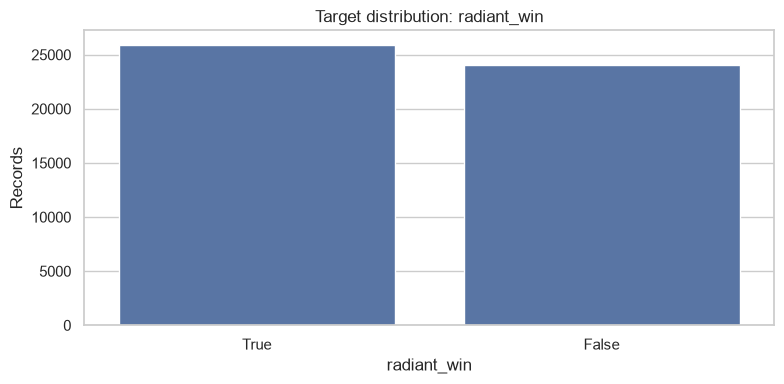

Players per match:


10    50000
Name: count, dtype: int64

Missing by player feature:


,missing
unit_order_vector_target_position,500000
unit_order_radar,500000
unit_order_taunt,500000
unit_order_continue,500000
unit_order_set_item_combine_lock,500000
...,...
item_3,0
level,0
item_5,0
leaver_status,0


In [6]:
overview(dota_matches)
overview(dota_players)
target_plot(dota_matches, "radiant_win")
print("Players per match:")
display(dota_players.groupby("match_id").size().value_counts())
print("Missing by player feature:")
display(dota_players.isna().sum().sort_values(ascending=False).to_frame("missing"))

Match-level pre-game attributes (categorical codes; group comparison is more informative than Pearson r):


,count,radiant_win_rate
game_mode,,
22,48670,0.519149
2,1330,0.508271


,count,radiant_win_rate
cluster,,
132,8204,0.509508
133,6801,0.520218
121,4168,0.519914
122,3645,0.528395
138,3442,0.515107
123,3091,0.519896
171,2514,0.519093
111,1913,0.514375
112,1861,0.501343


Hero pick frequency (descriptive; no join or modification of original CSV):


,pick_count
hero_id,
21,20881
11,17007
74,11676
7,11323
28,11181
39,10590
8,10394
100,10306
73,9823


Post-match fields are explored as descriptive outcomes only:


,feature,IQR_outliers,percent
0,duration,647,1.29
1,first_blood_time,915,1.83
2,positive_votes,548,1.10


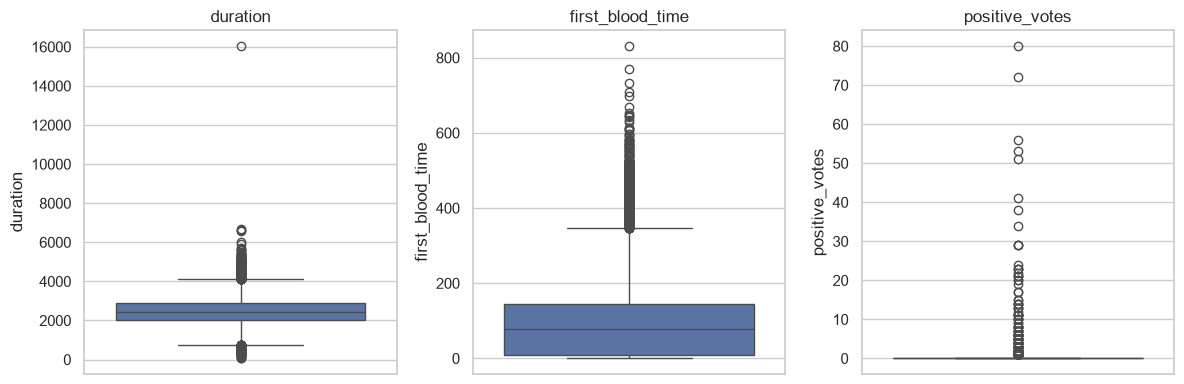

For later pre-game prediction, join hero selections by match_id and aggregate by team; do not use performance statistics.


In [7]:
# Pre-game features from the match table are limited; hero picks live in players.csv.
# Do NOT correlate final towers, barracks, duration or first blood with pre-match outcomes.
dota_pre_match = [c for c in ["game_mode", "cluster"] if c in dota_matches.columns]
print("Match-level pre-game attributes (categorical codes; group comparison is more informative than Pearson r):")
for col in dota_pre_match:
    display(dota_matches.groupby(col, dropna=False)["radiant_win"].agg(["count", "mean"]).rename(columns={"mean":"radiant_win_rate"}).sort_values("count", ascending=False).head(12))

print("Hero pick frequency (descriptive; no join or modification of original CSV):")
display(dota_players["hero_id"].value_counts().head(15).to_frame("pick_count"))

print("Post-match fields are explored as descriptive outcomes only:")
outlier_summary(dota_matches, ["duration", "first_blood_time", "positive_votes"])
print("For later pre-game prediction, join hero selections by match_id and aggregate by team; do not use performance statistics.")

In [8]:
def dota_player_definition(col):
    known = {"match_id":"Match identifier", "account_id":"Player account identifier", "hero_id":"Selected hero", "player_slot":"Team and slot", "kills":"Hero eliminations", "deaths":"Player deaths", "assists":"Assisted eliminations", "gold":"End-of-match gold", "gold_spent":"Total gold spent", "gold_per_min":"Gold earned per minute", "xp_per_min":"Experience earned per minute", "last_hits":"Last hits", "denies":"Denied allied units", "level":"Final hero level", "hero_damage":"Damage to heroes", "hero_healing":"Healing to heroes", "tower_damage":"Damage to towers", "leaver_status":"Player departure status"}
    if col in known: return known[col]
    if col.startswith("unit_order_"): return "Count of gameplay command: " + col.removeprefix("unit_order_").replace("_", " ")
    if col.startswith("item_"): return "Item identifier in inventory slot " + col.split("_")[-1]
    if col.startswith("xp_"): return "Experience from " + col.removeprefix("xp_")
    if col.startswith("gold_"): return "Gold associated with " + col.removeprefix("gold_").replace("_", " ")
    return "Recorded player performance field"
display(pd.DataFrame({"column": dota_players.columns, "description": [dota_player_definition(c) for c in dota_players.columns], "dtype": dota_players.dtypes.astype(str).values, "missing": dota_players.isna().sum().values}))

,column,description,dtype,missing
0,match_id,Match identifier,int64,0
1,account_id,Player account identifier,int64,0
2,hero_id,Selected hero,int64,0
3,player_slot,Team and slot,int64,0
4,gold,End-of-match gold,int64,0
...,...,...,...,...
68,unit_order_patrol,Count of gameplay command: patrol,float64,500000
69,unit_order_vector_target_position,Count of gameplay command: vector target position,float64,500000
70,unit_order_radar,Count of gameplay command: radar,float64,500000
71,unit_order_set_item_combine_lock,Count of gameplay command: set item combine lock,float64,500000


# Proposal 3: TMDB Movies — Audience Rating Prediction

### SMART-informed problem statement (historical study scope)
The TMDB sample contains 17,978 movies released from 2010 to 2025, but the distribution of audience ratings varies across titles and may be influenced by how many users voted. Film studios and distributors considering a release have limited advance evidence of audience reception, creating uncertainty in planning. The challenge is to assess whether characteristics known before release can meaningfully estimate later TMDB ratings without relying on post-release information.

**Time boundary:** The analysis in Lightning Talk #1 uses the uploaded historical dataset; predictive modeling is reserved for the final-project phase. No submission deadline is assumed beyond the instructor’s schedule.

### Measurable project objectives
1. Summarize vote_average and vote_count distributions for the 17,978 movies and compare rating patterns by release year and genre.
2. Examine coverage and missingness of candidate pre-release features, including budget, runtime and genre.
3. During the final project, compare rating predictions with a mean-rating baseline using MAE and RMSE, with an explicit minimum-vote sensitivity check.

**Scope note:** The figures describe the uploaded historical dataset, not a measured business loss. The modeling targets and performance metrics are proposed goals, not achieved results.

### Potential audience
Film studios, distributors, production teams and entertainment analysts.

### Goals and success criteria
Build a regression baseline later; assess MAE/RMSE; explore differences by genre and production attributes.

### Data source and collection
[https://zenodo.org/records/21920642](https://zenodo.org/records/21920642). Downloaded CSV or converted original source to CSV.

### Data information
movies_raw.csv: 17,978 rows × 16 columns.

### Target
`vote_average`: numerical average user rating; **continuous regression target**. Check skew, extreme values, and sample size behind ratings. `vote_count` and `popularity` are observed after release and should not be predictors for a pre-release model.

### Data dictionary (all 16 original columns)

| Column | Meaning |
|---|---|
| `movie_id` | TMDB movie identifier |
| `title` | Movie title |
| `release_date` | Release date |
| `status` | Release status |
| `budget` | Reported production budget |
| `revenue` | Reported revenue (post-release) |
| `runtime` | Duration in minutes |
| `genres` | Genre categories |
| `production_companies` | Production companies |
| `production_countries` | Production countries |
| `spoken_languages` | Languages spoken |
| `original_language` | Original language |
| `vote_average` | Average TMDB user rating; target |
| `vote_count` | Number of user ratings (post-release) |
| `popularity` | TMDB popularity score (time-dependent) |
| `adult` | Adult-content flag |

**Data limitation:** Financial zeros may mean unknown, and ratings with very few votes may be less reliable. Inspect before selecting a modeling approach.

Shape: (17978, 16) | Duplicate rows: 0
Numeric columns: 7
Non-numeric columns: 9


,movie_id,title,release_date,status,budget,revenue,runtime,genres,production_companies,production_countries,spoken_languages,original_language,vote_average,vote_count,popularity,adult
0,113727,Dark Seduction,2010-01-01,Released,0,0,89,Drama|Thriller|Romance,Lionsgate,Mexico,Español,es,6.799,102,1.6261,False
1,67250,12,2010-01-01,Released,0,0,3,Comedy,NaN,United States of America,English,en,5.000,57,0.3124,False
2,43615,"Lula, the Son of Brazil",2010-01-01,Released,9500000,3785593,130,Drama|History,LC Barreto|Filmes do Equador|InterVideo Produc...,Brazil,Português,pt,5.500,90,1.3337,False
3,38883,Protect and Serve,2010-01-03,Released,0,3807808,90,Comedy|Crime|Action,M6 Films|Same Player|Pathé|SCOPE Pictures|Webe...,France,Français,fr,4.500,106,0.5622,False
4,62105,Re-Cut,2010-01-04,Released,0,0,80,Horror|Thriller,Fritz Manger Productions|National Picture Show,United States of America,NaN,en,6.535,115,0.7341,False


,dtype,missing,missing_%
movie_id,int64,0,0.00
title,str,0,0.00
release_date,str,0,0.00
status,str,0,0.00
budget,int64,0,0.00
revenue,int64,0,0.00
runtime,int64,0,0.00
genres,str,10,0.06
production_companies,str,494,2.75
production_countries,str,176,0.98


count    17978.000000
mean         6.329466
std          0.881686
min          1.832000
25%          5.786000
50%          6.380500
75%          6.947000
max          9.900000
Name: vote_average, dtype: float64


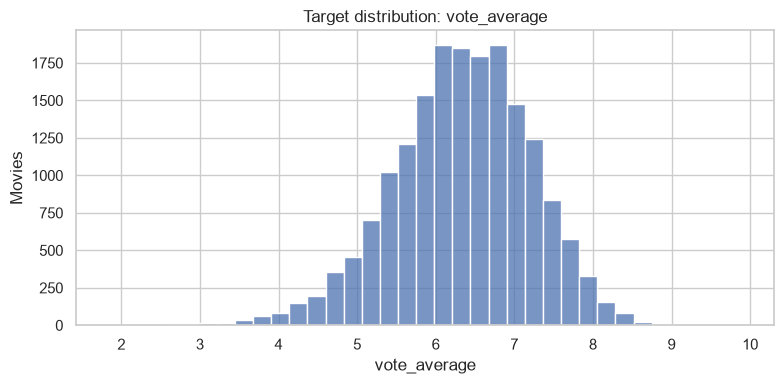

Movie rating count statistics:


,vote_average,vote_count,budget,revenue
count,17978.000000,17978.000000,1.797800e+04,1.797800e+04
mean,6.329466,740.979086,8.389049e+06,2.359657e+07
std,0.881686,2122.977234,2.863707e+07,1.096575e+08
min,1.832000,50.000000,0.000000e+00,0.000000e+00
25%,5.786000,80.000000,0.000000e+00,0.000000e+00
50%,6.380500,152.000000,0.000000e+00,0.000000e+00
75%,6.947000,427.750000,2.300000e+06,1.869959e+06
max,9.900000,40365.000000,6.588000e+08,2.799439e+09


Zero budget: 12463 | Zero revenue: 11156
Constant columns: ['status', 'adult']


In [9]:
overview(movies)
target_plot(movies, "vote_average", categorical=False)
print("Movie rating count statistics:")
display(movies[["vote_average", "vote_count", "budget", "revenue"]].describe())
print("Zero budget:", (movies.budget == 0).sum(), "| Zero revenue:", (movies.revenue == 0).sum())
print("Constant columns:", movies.columns[movies.nunique(dropna=False) == 1].tolist())

Pre-release candidate feature correlations with vote_average:


,correlation
runtime,0.131843
budget,0.100207


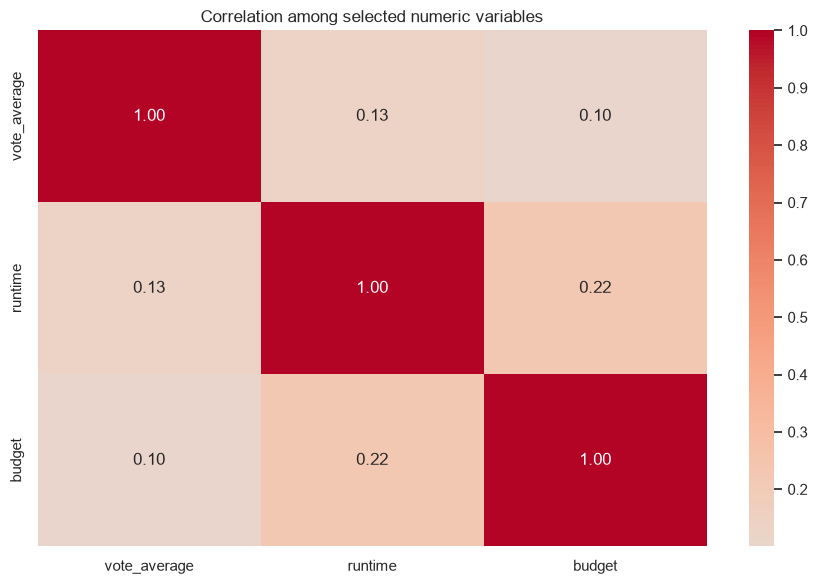

,feature,IQR_outliers,percent
0,vote_average,206,1.15
1,runtime,1431,7.96
2,budget,3512,19.53
3,vote_count,2594,14.43


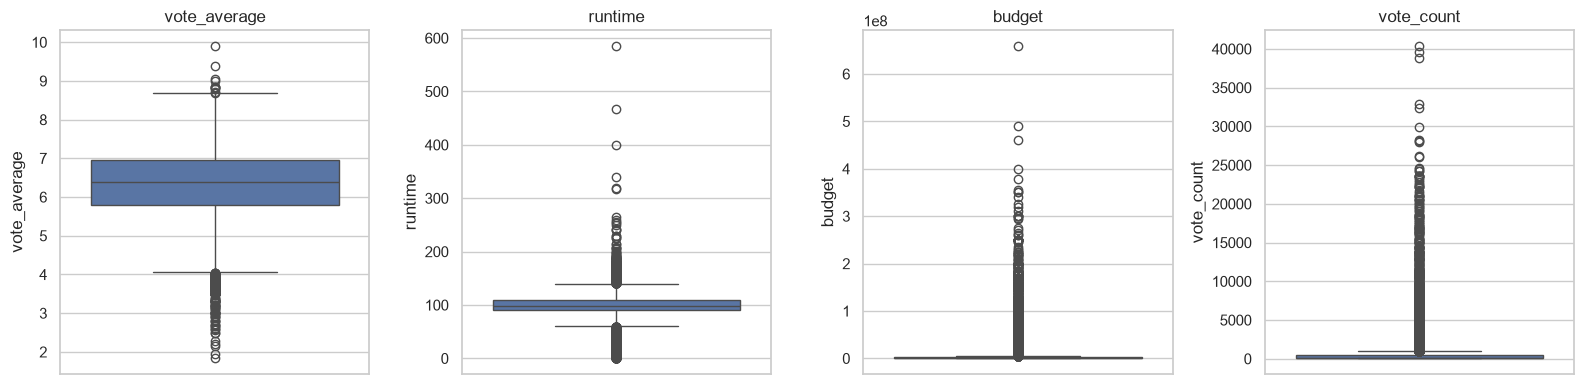

Excluded from predictive correlation: vote_count, popularity, revenue (post-release), movie_id (identifier).


In [10]:
# Correlations below use only plausible pre-release numeric predictors.
# Zero budgets may mean unknown, so interpret with caution.
movie_pre_release = [c for c in ["budget", "runtime"] if c in movies.columns]
movie_corr = movies[movie_pre_release + ["vote_average"]].copy()
print("Pre-release candidate feature correlations with vote_average:")
numeric_correlations(movie_corr, "vote_average")
outlier_summary(movies, ["vote_average", "runtime", "budget", "vote_count"])
print("Excluded from predictive correlation: vote_count, popularity, revenue (post-release), movie_id (identifier).")

### Additional movie EDA — Ratings by release year and genre

The following plots compare movie ratings by year and genre using the existing CSV. Genres may contain multiple labels, so each movie can appear in multiple genre groups. The charts are descriptive; they do not establish causality or model performance. Ratings with few votes may be less reliable.


,movie_count,mean_rating
release_year,,
2010,892,6.205844
2011,958,6.198683
2012,976,6.136343
2013,1108,6.221046
2014,1210,6.200636
2015,1258,6.178648
2016,1315,6.213389
2017,1398,6.290823
2018,1426,6.348630


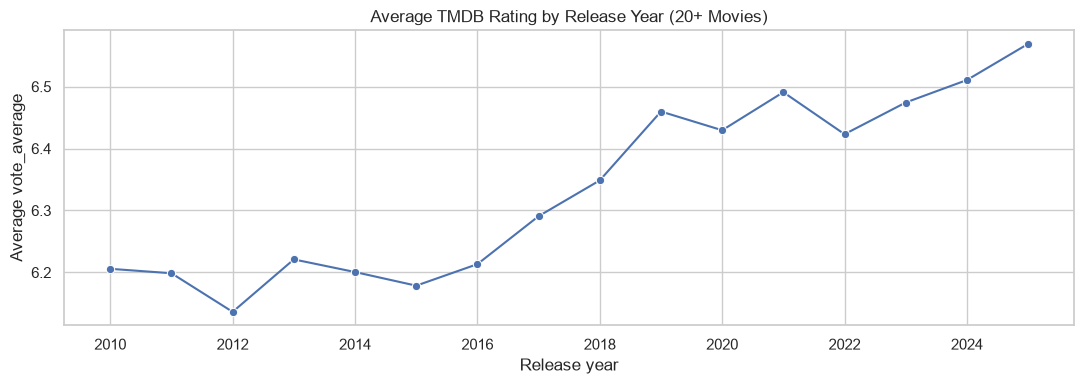

,movie_count,mean_rating
genre,,
Drama,7767,6.509224
Comedy,6002,6.239281
Thriller,4183,6.048874
Action,3284,6.245938
Horror,2734,5.699723
Romance,2573,6.442717
Crime,2024,6.347665
Adventure,1763,6.488627
Science Fiction,1575,6.097411


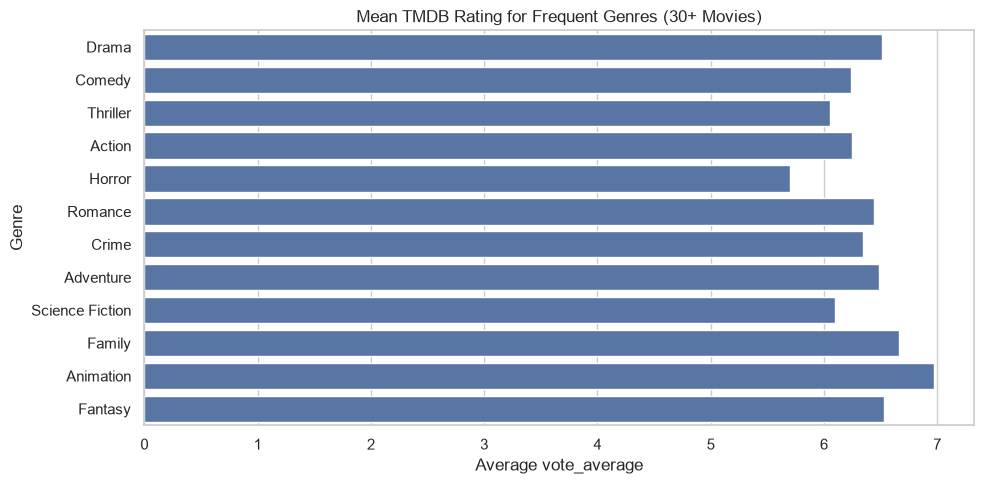

In [11]:
movie_eda = movies[["release_date", "genres", "vote_average", "vote_count"]].copy()
movie_eda["release_year"] = pd.to_datetime(movie_eda["release_date"], errors="coerce").dt.year
by_year = movie_eda.groupby("release_year", dropna=True).agg(
    movie_count=("vote_average", "size"),
    mean_rating=("vote_average", "mean")
).query("movie_count >= 20")
display(by_year)
plt.figure(figsize=(11, 4))
sns.lineplot(x=by_year.index, y=by_year["mean_rating"], marker="o")
plt.title("Average TMDB Rating by Release Year (20+ Movies)")
plt.xlabel("Release year"); plt.ylabel("Average vote_average")
plt.tight_layout(); plt.show()

# Some datasets encode genres with commas or vertical bars; detect the delimiter.
raw_genres = movie_eda["genres"].dropna().astype(str)
separator = "|" if raw_genres.str.contains("|", regex=True).mean() > 0.5 else ","
genre_rows = movie_eda.assign(genre=movie_eda["genres"].fillna("").astype(str).str.split(separator)).explode("genre")
genre_rows["genre"] = genre_rows["genre"].astype(str).str.strip().str.strip("[]'\" ")
genre_rows = genre_rows[genre_rows["genre"].ne("")]
by_genre = genre_rows.groupby("genre").agg(
    movie_count=("vote_average", "size"),
    mean_rating=("vote_average", "mean")
).query("movie_count >= 30").sort_values("movie_count", ascending=False).head(12)
display(by_genre)
plt.figure(figsize=(10, 5))
sns.barplot(data=by_genre.reset_index(), x="mean_rating", y="genre")
plt.title("Mean TMDB Rating for Frequent Genres (30+ Movies)")
plt.xlabel("Average vote_average"); plt.ylabel("Genre")
plt.tight_layout(); plt.show()


# Final Comparison and Recommendation Framework

| Candidate | Size | Target | Type | Main limitation |
|---|---|---|---|---|
| European Soccer | 25,979 × 115 | Match result | 3-class classification | Extensive missing fields; pre/post-match leakage |
| Dota 2 Matches | 50,000 × 13 (+ 500,000 player records) | Radiant win | Binary classification | Hero data require match-level aggregation; post-match leakage |
| TMDB Movies | 17,978 × 16 | Average rating | Regression | Missing financial data and rating reliability |

**Next steps (after approval):** Choose one proposal, define prediction time, establish a baseline, decide on permissible features, plan splitting, then preprocess and model.

**Submission checklist:** Send the three dataset source links to IAs via Slack for approval; submit this notebook and the slide deck in Google Classroom by the stated deadline. The guideline lists **November 2** for the presentation and notebook/slides submission; confirm the schedule with the instructor.